In [1]:
import pandas as pd
from pathlib import Path

base_dir = Path("/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/traitar/acquisition_new/results")  # your main results folder

all_dfs = []

for sgb_dir in base_dir.iterdir():
    if not sgb_dir.is_dir():
        continue
    
    sgb_id = sgb_dir.name  # e.g. "10068"
    
    file = sgb_dir / "traitar" / "phenotype_prediction" / "predictions_flat_majority-votes_combined.txt"
    
    if file.exists():
        df = pd.read_csv(file, sep="\t")
        
        # Add correct SGB identifier to match your transmissibility table
        df["sgb"] = f"t__SGB{sgb_id}"
        
        all_dfs.append(df)

# Combine all SGB trait predictions
traits_df = pd.concat(all_dfs, ignore_index=True)

# Move sgb column to front
cols = ["sgb"] + [c for c in traits_df.columns if c != "sgb"]
traits_df = traits_df[cols]

# Save master trait matrix
traits_df.to_csv("all_sgb_traitar_traits.tsv", sep="\t", index=False)


In [2]:
traits_df.head()

,sgb,sample,phenotype,score,phenotype_model
0,t__SGB6962,6962,Growth on ordinary blood agar,1,phypat
1,t__SGB6962,6962,Growth on ordinary blood agar,1,phypat+PGL
2,t__SGB6962,6962,Trehalose,1,phypat
3,t__SGB6962,6962,Trehalose,1,phypat+PGL
4,t__SGB6962,6962,Bacillus or coccobacillus,1,phypat


In [3]:
traits_df = traits_df[traits_df["phenotype_model"] == "phypat+PGL"]
print(traits_df)

               sgb  sample                      phenotype  score  \
1       t__SGB6962    6962  Growth on ordinary blood agar      1   
3       t__SGB6962    6962                      Trehalose      1   
5       t__SGB6962    6962      Bacillus or coccobacillus      1   
7       t__SGB6962    6962                     D-Mannitol      1   
9       t__SGB6962    6962              Glucose fermenter      1   
...            ...     ...                            ...    ...   
12383  t__SGB15203   15203                        Maltose      1   
12385  t__SGB15203   15203           Tartrate utilization      1   
12387  t__SGB15203   15203                  Gram positive      1   
12389  t__SGB15203   15203      Bacillus or coccobacillus      1   
12391  t__SGB15203   15203                 Growth at 42°C      1   

      phenotype_model  
1          phypat+PGL  
3          phypat+PGL  
5          phypat+PGL  
7          phypat+PGL  
9          phypat+PGL  
...               ...  
12383      phyp

In [4]:
# Ensure one value per (SGB, phenotype)
traits_df = (
    traits_df
    .groupby(["sgb", "phenotype"], as_index=False)["score"]
    .max()  # trait present if predicted in any genome
)

In [5]:
trait_matrix = traits_df.pivot(
    index="sgb",
    columns="phenotype",
    values="score"
).fillna(0)

# Convert to integers (0/1)
trait_matrix = trait_matrix.astype(int)

print("Trait matrix shape (SGBs x traits):", trait_matrix.shape)

Trait matrix shape (SGBs x traits): (523, 64)


In [6]:
trait_matrix.to_csv("sgb_traitar_traits_matrix.tsv", sep="\t")

In [7]:
# Load transmissibility data
trans = pd.read_csv("sgb_transmissibility_annotated.tsv", sep="\t")

# Move sgb from index to column
trait_matrix = trait_matrix.reset_index()

# Normalize SGB IDs for merging
trait_matrix["_sgb_merge"] = trait_matrix["sgb"].str.replace(
    r"_group$", "", regex=True
)

trans["_sgb_merge"] = trans["sgb"].str.replace(
    r"_group$", "", regex=True
)

# Remove duplicate Traitar entries after normalization
trans = trans.drop_duplicates(subset="_sgb_merge")

# Merge
merged = trait_matrix.merge(
    trans,
    on="_sgb_merge",
    suffixes=("", "_trans")
)

# Remove temporary merge columns from BOTH dataframes
merged = merged.drop(columns="_sgb_merge")
trait_matrix = trait_matrix.drop(columns="_sgb_merge")

print("Merged SGBs:", len(merged))
print("Columns:", merged.columns[:10])

Merged SGBs: 343
Columns: Index(['sgb', 'Acetate utilization', 'Aerobe', 'Alkaline phosphatase',
       'Anaerobe', 'Arginine dihydrolase', 'Bacillus or coccobacillus',
       'Bile-susceptible', 'Capnophilic', 'Casein hydrolysis'],
      dtype='str')


In [8]:
trans.head()

,sgb,phylum,family,genus,n_datasets_present,n_recipients_with_donor_sgb,n_recipients_shared,combined_transmissibility,median_donor_abundance,n_donor_samples,log10_abundance,predicted_transmissibility,residual,mean_atleast2_CHM,_sgb_merge
0,t__SGB5818,Firmicutes,Veillonellaceae,Dialister,7,27,21,0.777778,0.022952,27,-1.639168,0.352132,0.425646,NaN,t__SGB5818
1,t__SGB1613,Bacteroidota,Prevotellaceae,Segatella,8,34,25,0.735294,0.054197,34,-1.266014,0.420575,0.314720,NaN,t__SGB1613
2,t__SGB1679,Bacteroidota,Prevotellaceae,Leyella,7,25,18,0.720000,0.042168,25,-1.375003,0.400584,0.319416,NaN,t__SGB1679
3,t__SGB2071,Bacteroidota,FGB629,GGB1495,11,41,29,0.707317,0.007405,41,-2.130428,0.262026,0.445291,NaN,t__SGB2071
4,t__SGB6783,Firmicutes,Coprobacillaceae,Catenibacterium,11,53,33,0.622642,0.007115,53,-2.147788,0.258842,0.363800,NaN,t__SGB6783


In [9]:
print(merged)
merged.head()

             sgb  Acetate utilization  Aerobe  Alkaline phosphatase  Anaerobe  \
0    t__SGB10068                    0       0                     1         0   
1    t__SGB14306                    0       0                     0         1   
2    t__SGB14311                    0       0                     1         1   
3    t__SGB14313                    0       0                     1         1   
4    t__SGB14322                    0       0                     0         1   
..           ...                  ...     ...                   ...       ...   
338   t__SGB9286                    0       1                     0         0   
339   t__SGB9342                    0       0                     0         0   
340   t__SGB9346                    0       0                     0         1   
341   t__SGB9347                    0       0                     0         0   
342   t__SGB9712                    0       0                     1         0   

     Arginine dihydrolase  

,sgb,Acetate utilization,Aerobe,Alkaline phosphatase,Anaerobe,Arginine dihydrolase,Bacillus or coccobacillus,Bile-susceptible,Capnophilic,Casein hydrolysis,...,n_datasets_present,n_recipients_with_donor_sgb,n_recipients_shared,combined_transmissibility,median_donor_abundance,n_donor_samples,log10_abundance,predicted_transmissibility,residual,mean_atleast2_CHM
0,t__SGB10068,0,0,1,0,0,1,1,0,1,...,19,72,3,0.041667,0.002284,72,-2.641057,0.168368,-0.126701,0.948558
1,t__SGB14306,0,0,0,1,0,1,0,0,0,...,22,88,13,0.147727,0.003028,89,-2.518715,0.190807,-0.043080,0.172768
2,t__SGB14311,0,0,1,1,1,1,0,0,0,...,19,58,4,0.068966,0.003207,59,-2.493711,0.195393,-0.126428,0.130913
3,t__SGB14313,0,0,1,1,1,1,1,0,0,...,11,24,1,0.041667,0.006352,24,-2.197004,0.249815,-0.208148,0.351384
4,t__SGB14322,0,0,0,1,0,0,0,0,0,...,12,57,26,0.456140,0.005646,58,-2.248190,0.240426,0.215714,NaN


In [10]:
min_prevalence = 0.05 * len(merged)

trait_cols = [c for c in trait_matrix.columns if c != "sgb"]

keep_traits = [
    t for t in trait_cols
    if merged[t].sum() >= min_prevalence
]

merged_filtered = merged[["sgb", "residual"] + keep_traits]

print("Traits kept after prevalence filter:", len(keep_traits))

Traits kept after prevalence filter: 38


In [11]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Define columns to exclude from trait testing
meta_cols = [
    "sgb",
    "residual",
    "n_datasets_present",
    "n_recipients_with_donor_sgb",
    "n_recipients_shared"
]

# Keep only trait columns that exist
trait_cols = [c for c in merged_filtered.columns if c not in meta_cols]

print("Number of traits being tested:", len(trait_cols))
print("Number of SGBs:", len(merged_filtered))

Number of traits being tested: 38
Number of SGBs: 343


In [12]:
merged_filtered.head()

,sgb,residual,Alkaline phosphatase,Anaerobe,Arginine dihydrolase,Bacillus or coccobacillus,Bile-susceptible,Casein hydrolysis,Citrate,Coagulase production,...,ONPG (beta galactosidase),Pyrrolidonyl-beta-naphthylamide,Raffinose,Salicin,Spore formation,Starch hydrolysis,Sucrose,Tartrate utilization,Trehalose,Urea hydrolysis
0,t__SGB10068,-0.126701,1,0,0,1,1,1,0,0,...,0,0,0,0,0,0,0,1,1,0
1,t__SGB14306,-0.043080,0,1,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,t__SGB14311,-0.126428,1,1,1,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,t__SGB14313,-0.208148,1,1,1,1,1,0,0,0,...,0,1,0,0,1,0,0,1,0,0
4,t__SGB14322,0.215714,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
merged_filtered.to_csv(
    "traitar_to_SGBs.tsv",
    sep="\t",
    index=False
)

In [14]:
results = []

y = merged_filtered["residual"]

for trait in trait_cols:
    x = merged_filtered[trait]
    
    # Skip traits with no variation (safety)
    if x.nunique() < 2:
        continue
    
    rho, pval = spearmanr(x, y)
    
    # Effect size: mean transmissibility difference
    mean_with = y[x == 1].mean()
    mean_without = y[x == 0].mean()
    delta = mean_with - mean_without
    
    prevalence = x.mean()  # fraction of SGBs with trait
    
    results.append({
        "trait": trait,
        "spearman_rho": rho,
        "p_value": pval,
        "mean_trans_with_trait": mean_with,
        "mean_trans_without_trait": mean_without,
        "delta_mean_transmissibility": delta,
        "prevalence": prevalence
    })

results_df = pd.DataFrame(results)

In [15]:
results_df["FDR"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

# Sort by significance
results_df = results_df.sort_values("FDR")

In [16]:
# Show top 20 traits associated with transmissibility
results_df.head(20)

,trait,spearman_rho,p_value,mean_trans_with_trait,mean_trans_without_trait,delta_mean_transmissibility,prevalence,FDR
27,Motile,-0.331338,3.120095e-10,-0.084704,0.012465,-0.097169,0.128280,1.185636e-08
17,Gram negative,0.302105,1.139354e-08,0.073130,-0.018416,0.091546,0.201166,2.164772e-07
18,Gram positive,-0.280172,1.320717e-07,-0.018254,0.065227,-0.083481,0.781341,1.672909e-06
32,Spore formation,-0.223879,2.859323e-05,-0.042919,0.015268,-0.058187,0.262391,2.716357e-04
21,Hydrogen sulfide,0.204706,1.346010e-04,0.063271,-0.008117,0.071388,0.113703,1.022968e-03
5,Casein hydrolysis,0.195799,2.638920e-04,0.049551,-0.009463,0.059014,0.160350,1.671316e-03
20,Growth on ordinary blood agar,0.168357,1.754067e-03,0.004010,-0.072409,0.076420,0.947522,7.799908e-03
15,Gelatin hydrolysis,0.169051,1.677549e-03,0.063211,-0.005619,0.068829,0.081633,7.799908e-03
26,Melibiose,0.167548,1.847347e-03,0.039271,-0.004893,0.044164,0.110787,7.799908e-03
1,Anaerobe,0.133629,1.325183e-02,0.002722,-0.049145,0.051867,0.947522,4.577904e-02


In [17]:
results_df.to_csv(
    "trait_transmissibility_associations.tsv",
    sep="\t",
    index=False
)

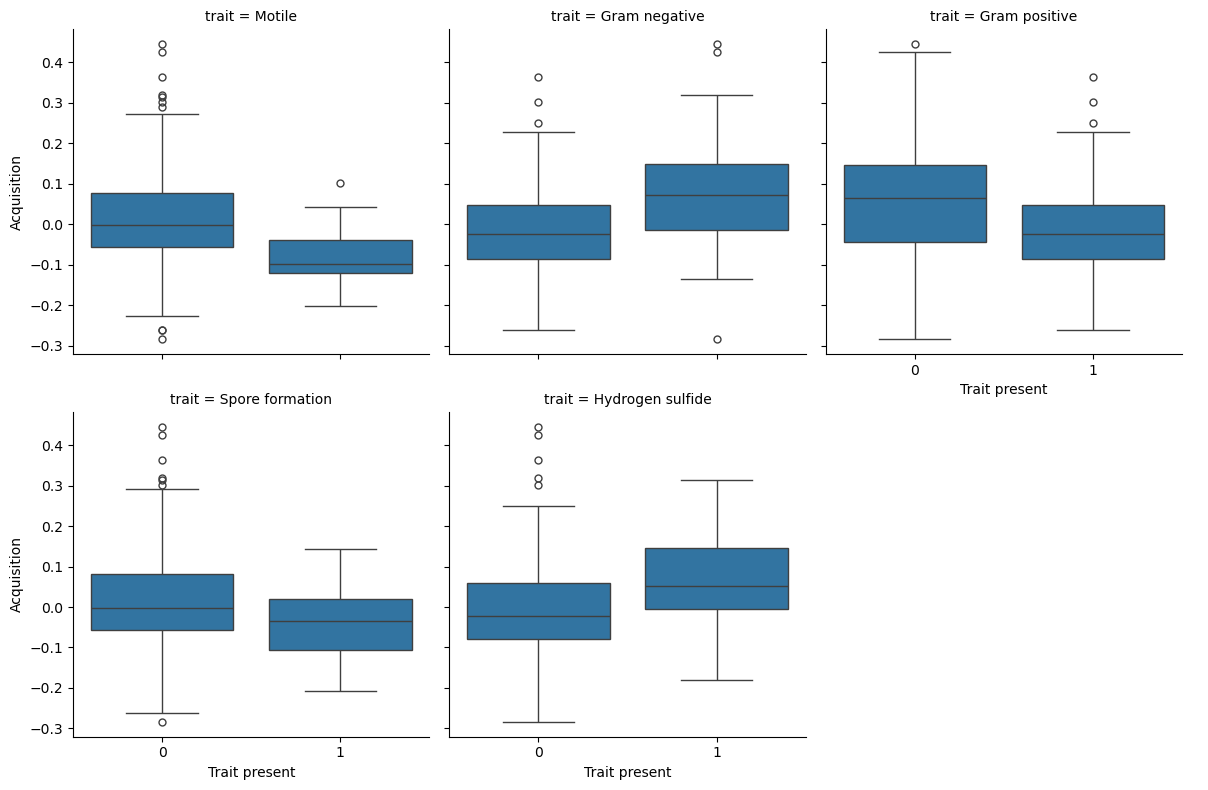

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sig_traits = results_df[results_df["FDR"] < 0.05]["trait"].head(5)

# reshape dataframe
plot_df = merged_filtered.melt(
    id_vars="residual",
    value_vars=sig_traits,
    var_name="trait",
    value_name="presence"
)

g = sns.catplot(
    data=plot_df,
    x="presence",
    y="residual",
    col="trait",
    kind="box",
    col_wrap=3,
    height=4,
    sharey=True
)

g.set_axis_labels("Trait present", "Acquisition")
plt.show()

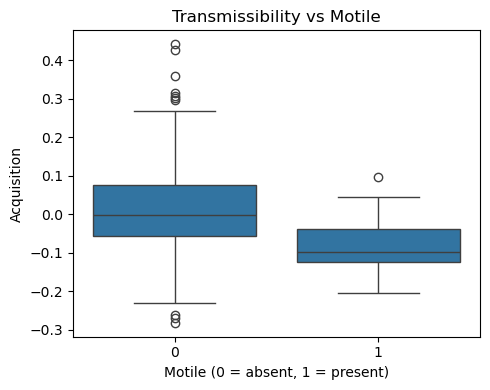

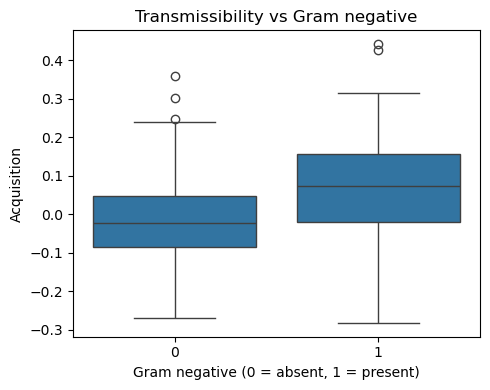

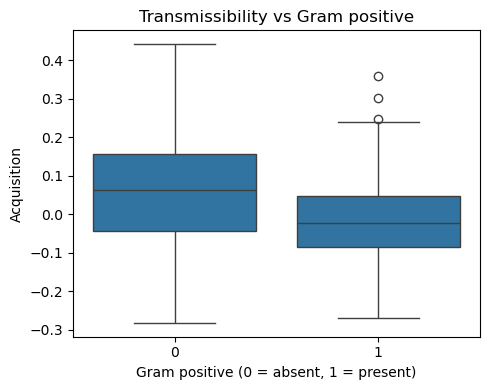

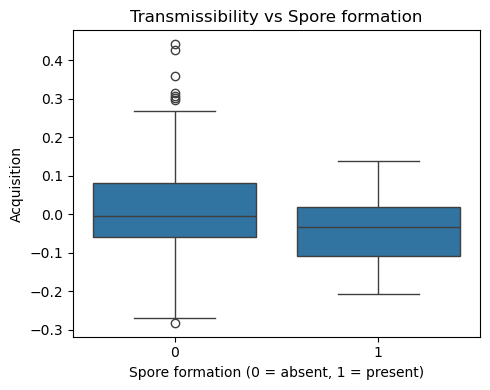

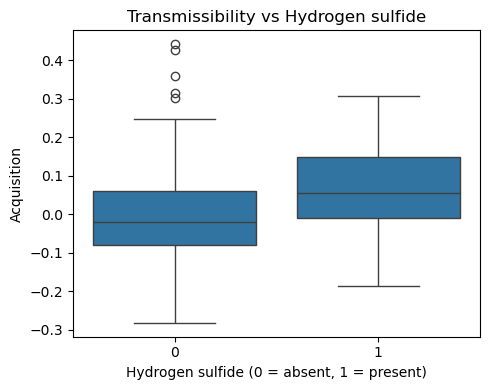

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select significant traits (adjust threshold as needed)
sig_traits = results_df[results_df["FDR"] < 0.05]["trait"].head(5)

for trait in sig_traits:
    plt.figure(figsize=(5, 4))
    sns.boxplot(
        x=merged_filtered[trait],
        y=merged_filtered["residual"]
    )
    plt.xlabel(f"{trait} (0 = absent, 1 = present)")
    plt.ylabel("Acquisition")
    plt.title(f"Transmissibility vs {trait}")
    plt.tight_layout()
    plt.show()